# Luminance and contrast across stimulus categories

This notebook checks whether the 9 categories in `stimuli_list.csv` (3,300 images; `Exclude` not included) differ in **mean luminance** and **RMS contrast**.

**Measures (per image)**
- Each image is converted to grayscale with PIL (`L` mode, ITU-R 601 luma: 0.299R + 0.587G + 0.114B) and scaled to 0–1.
- **Mean luminance** = mean grayscale pixel value.
- **RMS contrast** = standard deviation of the grayscale pixel values.

These are pixel-intensity measures. They are not physical luminance (cd/m²), which depends on the monitor and its calibration.

**Statistics**
The 20 images in a subcategory are not independent of each other, so the main tests are run on the **165 subcategory means**. Image-level tests and a mixed model with subcategory as a random effect are included for comparison.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from scipy import stats
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)  # statsmodels re-enables this on import

ROOT = Path(".")
df = pd.read_csv(ROOT / "stimuli_list.csv")
print(df.shape)
df.head()

(3300, 7)


,image_id,category,subcategory,exemplar,filename,path,source
0,img0001,Animals,bee,1,bee_02s.jpg,Animals24/bee/bee_02s.jpg,THINGS
1,img0002,Animals,bee,2,bee_03s.jpg,Animals24/bee/bee_03s.jpg,THINGS
2,img0003,Animals,bee,3,bee_06s.jpg,Animals24/bee/bee_06s.jpg,THINGS
3,img0004,Animals,bee,4,bee_07s.jpg,Animals24/bee/bee_07s.jpg,THINGS
4,img0005,Animals,bee,5,bee_08s.jpg,Animals24/bee/bee_08s.jpg,THINGS


## 1. Compute luminance and contrast for every image

In [2]:
def lum_contrast(path):
    g = np.asarray(Image.open(ROOT / path).convert("L"), dtype=np.float64) / 255.0
    return g.mean(), g.std()

vals = np.array([lum_contrast(p) for p in df["path"]])
df["mean_luminance"] = vals[:, 0]
df["rms_contrast"] = vals[:, 1]

df.to_csv(ROOT / "image_luminance_contrast.csv", index=False)
df[["mean_luminance", "rms_contrast"]].describe().round(3)

,mean_luminance,rms_contrast
count,3300.000,3300.000
mean,0.490,0.218
std,0.129,0.056
min,0.033,0.059
25%,0.409,0.179
50%,0.481,0.218
75%,0.566,0.258
max,0.921,0.406


## 2. Descriptives by category

In [3]:
MEASURES = {"mean_luminance": "Mean luminance (0–1)", "rms_contrast": "RMS contrast"}
cat_order = sorted(df["category"].unique())

desc = (df.groupby("category")[list(MEASURES)]
          .agg(["mean", "std", "min", "max"])
          .round(3))
desc

mean_luminance                      rms_contrast  \
                                      mean    std    min    max         mean   
category                                                                       
Animals                              0.486  0.116  0.203  0.857        0.199   
Clothing:Accessories                 0.509  0.139  0.197  0.904        0.230   
Electronic_device:Appliance          0.495  0.124  0.173  0.827        0.237   
Fruit:Veggies                        0.477  0.110  0.202  0.832        0.218   
Furniture:Home_decor                 0.506  0.142  0.033  0.851        0.211   
Kitchenware                          0.532  0.157  0.068  0.899        0.190   
Musical_Instruments                  0.430  0.143  0.103  0.827        0.226   
Tools                                0.508  0.126  0.143  0.921        0.201   
Vehicles                             0.478  0.105  0.111  0.795        0.238   

                                                  
                               std    min    max  
category                                          
Animals                      0.050  0.059  0.336  
Clothing:Accessories         0.061  0.075  0.406  
Electronic_device:Appliance  0.052  0.076  0.364  
Fruit:Veggies                0.046  0.084  0.340  
Furniture:Home_decor         0.051  0.081  0.361  
Kitchenware                  0.061  0.059  0.366  
Musical_Instruments          0.056  0.094  0.389  
Tools                        0.053  0.070  0.339  
Vehicles                     0.056  0.075  0.392

## 3. Distributions
Each dot is one subcategory mean (20 images). The boxes show the spread of those means within each category.

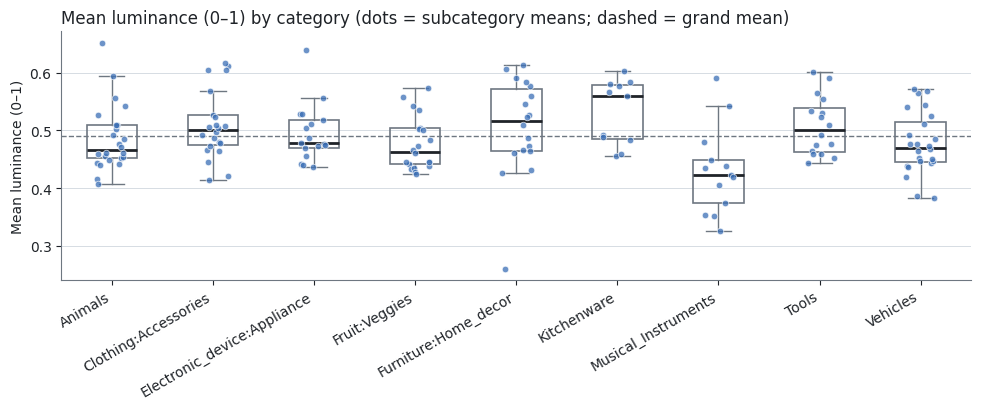

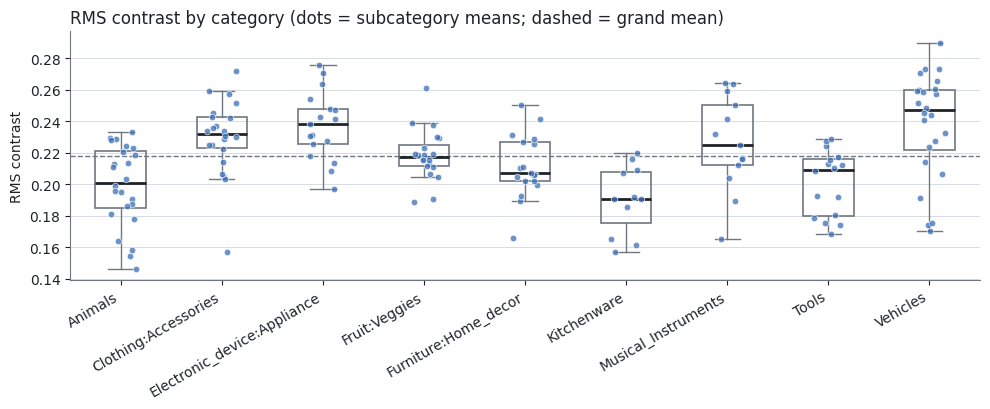

In [4]:
sub = (df.groupby(["category", "subcategory"])[list(MEASURES)]
         .mean().reset_index())

INK, MUTED, MARK = "#1f2328", "#6e7781", "#3b6fb6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": MUTED, "axes.labelcolor": INK,
                     "xtick.color": INK, "ytick.color": INK, "font.size": 10})

rng = np.random.default_rng(0)
for col, label in MEASURES.items():
    fig, ax = plt.subplots(figsize=(10, 4.2))
    data = [sub.loc[sub["category"] == c, col] for c in cat_order]
    ax.boxplot(data, widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="none", edgecolor=MUTED, linewidth=1.2),
               medianprops=dict(color=INK, linewidth=2),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for i, d in enumerate(data, 1):
        ax.scatter(i + rng.uniform(-0.15, 0.15, len(d)), d, s=22,
                   color=MARK, alpha=0.75, edgecolor="white", linewidth=0.6, zorder=3)
    ax.axhline(sub[col].mean(), color=MUTED, linestyle="--", linewidth=1)
    ax.set_xticks(range(1, len(cat_order) + 1))
    ax.set_xticklabels(cat_order, rotation=30, ha="right")
    ax.set_ylabel(label)
    ax.set_title(f"{label} by category (dots = subcategory means; dashed = grand mean)",
                 loc="left", color=INK)
    ax.grid(axis="y", color="#d0d7de", linewidth=0.6)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

## 4. Do categories differ? Omnibus tests

- **Subcategory level (main test):** one-way ANOVA and Kruskal–Wallis on the 165 subcategory means.
- **Mixed model:** image-level model with a random intercept for subcategory. A likelihood-ratio test compares it with and without category.
- **Image level (for reference only):** treats all 3,300 images as independent, so its p-values are too optimistic.

Effect sizes: η² for ANOVA, ε² for Kruskal–Wallis.

In [5]:
def omnibus(data, col):
    groups = [g[col].values for _, g in data.groupby("category")]
    k, n = len(groups), sum(len(g) for g in groups)
    F, pF = stats.f_oneway(*groups)
    H, pH = stats.kruskal(*groups)
    grand = data[col].mean()
    ss_b = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
    ss_t = ((data[col] - grand) ** 2).sum()
    return {"F": F, "p_ANOVA": pF, "eta_sq": ss_b / ss_t,
            "H": H, "p_KW": pH, "epsilon_sq": (H - k + 1) / (n - k)}

def mixed_lrt(col):
    full = smf.mixedlm(f"{col} ~ C(category)", df, groups=df["subcategory"]).fit(reml=False)
    null = smf.mixedlm(f"{col} ~ 1", df, groups=df["subcategory"]).fit(reml=False)
    lr = 2 * (full.llf - null.llf)
    dof = len(cat_order) - 1
    return {"LR_chi2": lr, "df": dof, "p_LRT": stats.chi2.sf(lr, dof)}

rows = []
for col in MEASURES:
    rows.append({"measure": col, "level": "subcategory means (n=165)", **omnibus(sub, col)})
    rows.append({"measure": col, "level": "images (n=3300, not independent)", **omnibus(df, col)})
omni = pd.DataFrame(rows).set_index(["measure", "level"])
display(omni.style.format({"F": "{:.2f}", "H": "{:.2f}", "eta_sq": "{:.3f}",
                           "epsilon_sq": "{:.3f}", "p_ANOVA": "{:.2g}", "p_KW": "{:.2g}"}))

mixed = pd.DataFrame({col: mixed_lrt(col) for col in MEASURES}).T
mixed.style.format({"LR_chi2": "{:.2f}", "df": "{:.0f}", "p_LRT": "{:.2g}"})

,LR_chi2,df,p_LRT
mean_luminance,25.29,8,0.0014
rms_contrast,60.54,8,3.6e-10


## 5. Which categories differ? Tukey HSD on subcategory means
Only the significant pairs are shown (family-wise α = .05).

In [6]:
for col, label in MEASURES.items():
    t = pairwise_tukeyhsd(sub[col], sub["category"], alpha=0.05)
    res = pd.DataFrame(t.summary().data[1:], columns=t.summary().data[0])
    sig = res[res["reject"]].sort_values("meandiff", key=abs, ascending=False)
    print(f"\n{label}: {len(sig)} of {len(res)} pairs differ significantly")
    display(sig.reset_index(drop=True))


Mean luminance (0–1): 4 of 36 pairs differ significantly


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Kitchenware,Musical_Instruments,-0.1018,0.0016,-0.1786,-0.0250,True
1,Clothing:Accessories,Musical_Instruments,-0.0791,0.0064,-0.1447,-0.0136,True
2,Musical_Instruments,Tools,0.0782,0.0165,0.0082,0.1482,True
3,Furniture:Home_decor,Musical_Instruments,-0.0761,0.0168,-0.1443,-0.0078,True



RMS contrast: 12 of 36 pairs differ significantly


,group1,group2,meandiff,p-adj,lower,upper,reject
0,Kitchenware,Vehicles,0.0476,0.0000,0.0194,0.0759,True
1,Electronic_device:Appliance,Kitchenware,-0.0468,0.0001,-0.0769,-0.0168,True
2,Clothing:Accessories,Kitchenware,-0.0394,0.0009,-0.0681,-0.0107,True
3,Animals,Vehicles,0.0389,0.0000,0.0165,0.0613,True
4,Animals,Electronic_device:Appliance,0.0380,0.0001,0.0134,0.0626,True
5,Tools,Vehicles,0.0369,0.0003,0.0119,0.0619,True
6,Electronic_device:Appliance,Tools,-0.0361,0.0015,-0.0631,-0.0090,True
7,Kitchenware,Musical_Instruments,0.0357,0.0155,0.0039,0.0675,True
8,Animals,Clothing:Accessories,0.0306,0.0014,0.0077,0.0535,True
9,Clothing:Accessories,Tools,-0.0287,0.0153,-0.0541,-0.0032,True


## 6. Possible confound: image source
Images come from THINGS, ImageNet and other sources, and the sources are not spread evenly across categories. If the sources differ systematically, that could partly explain category differences.

In [7]:
display(pd.crosstab(df["category"], df["source"]))
display(df.groupby("source")[list(MEASURES)].agg(["mean", "std", "count"]).round(3))
for col in MEASURES:
    m = smf.mixedlm(f"{col} ~ C(category) + C(source)", df, groups=df["subcategory"]).fit(reml=False)
    m0 = smf.mixedlm(f"{col} ~ C(source)", df, groups=df["subcategory"]).fit(reml=False)
    lr = 2 * (m.llf - m0.llf)
    print(f"{col}: category effect controlling for source  LR chi2({len(cat_order)-1}) = {lr:.2f}, "
          f"p = {stats.chi2.sf(lr, len(cat_order)-1):.2g}")

source,ImageNet,Other,THINGS
category,,,
Animals,90,0,390
Clothing:Accessories,68,28,344
Electronic_device:Appliance,77,10,253
Fruit:Veggies,116,3,281
Furniture:Home_decor,74,0,286
Kitchenware,62,10,148
Musical_Instruments,67,4,189
Tools,105,1,214
Vehicles,141,6,333


mean_luminance              rms_contrast             
                   mean    std count         mean    std count
source                                                        
ImageNet          0.456  0.127   800        0.224  0.056   800
Other             0.543  0.162    62        0.222  0.072    62
THINGS            0.500  0.127  2438        0.216  0.055  2438

mean_luminance: category effect controlling for source  LR chi2(8) = 25.28, p = 0.0014
rms_contrast: category effect controlling for source  LR chi2(8) = 60.63, p = 3.5e-10


## 7. Variation within categories

How spread out luminance and contrast are inside each category. The questions are:
1. How much of the total variation lies between categories, between subcategories, and between images within a subcategory?
2. Are some categories more variable than others?
3. Which subcategories are the most and least variable?
4. Which individual images are extreme (|z| > 3 relative to all 3,300 images)?

In [8]:
rows = []
for col in MEASURES:
    gm = df[col].mean()
    tot = ((df[col] - gm) ** 2).sum()
    cm = df.groupby("category")[col].transform("mean")
    sm = df.groupby("subcategory")[col].transform("mean")
    rows.append({"measure": col,
                 "between categories %": 100 * ((cm - gm) ** 2).sum() / tot,
                 "between subcategories (within category) %": 100 * ((sm - cm) ** 2).sum() / tot,
                 "between images (within subcategory) %": 100 * ((df[col] - sm) ** 2).sum() / tot})
pd.DataFrame(rows).set_index("measure").round(1)

,between categories %,between subcategories (within category) %,between images (within subcategory) %
measure,,,
mean_luminance,3.3,20.1,76.5
rms_contrast,8.1,18.3,73.5


### Spread within each category
SD, coefficient of variation (CV = SD / mean), interquartile range and range. Levene's test (median-centred) checks whether the spread differs between categories.

In [9]:
for col, label in MEASURES.items():
    g = df.groupby("category")[col]
    spread = pd.DataFrame({"SD": g.std(), "CV %": 100 * g.std() / g.mean(),
                           "IQR": g.quantile(.75) - g.quantile(.25),
                           "min": g.min(), "max": g.max()}).round(3)
    lev = stats.levene(*[x.values for _, x in g], center="median")
    print(f"\n{label}: Levene W = {lev.statistic:.2f}, p = {lev.pvalue:.2g}")
    display(spread)


Mean luminance (0–1): Levene W = 10.29, p = 2.5e-14


,SD,CV %,IQR,min,max
category,,,,,
Animals,0.116,23.966,0.139,0.203,0.857
Clothing:Accessories,0.139,27.220,0.186,0.197,0.904
Electronic_device:Appliance,0.124,25.075,0.159,0.173,0.827
Fruit:Veggies,0.110,23.045,0.136,0.202,0.832
Furniture:Home_decor,0.142,28.106,0.174,0.033,0.851
Kitchenware,0.157,29.516,0.210,0.068,0.899
Musical_Instruments,0.143,33.171,0.168,0.103,0.827
Tools,0.126,24.863,0.158,0.143,0.921
Vehicles,0.105,21.961,0.129,0.111,0.795



RMS contrast: Levene W = 6.60, p = 1.4e-08


,SD,CV %,IQR,min,max
category,,,,,
Animals,0.050,25.022,0.070,0.059,0.336
Clothing:Accessories,0.061,26.456,0.089,0.075,0.406
Electronic_device:Appliance,0.052,22.025,0.075,0.076,0.364
Fruit:Veggies,0.046,20.843,0.058,0.084,0.340
Furniture:Home_decor,0.051,24.192,0.075,0.081,0.361
Kitchenware,0.061,32.246,0.077,0.059,0.366
Musical_Instruments,0.056,24.768,0.076,0.094,0.389
Tools,0.053,26.347,0.069,0.070,0.339
Vehicles,0.056,23.339,0.073,0.075,0.392


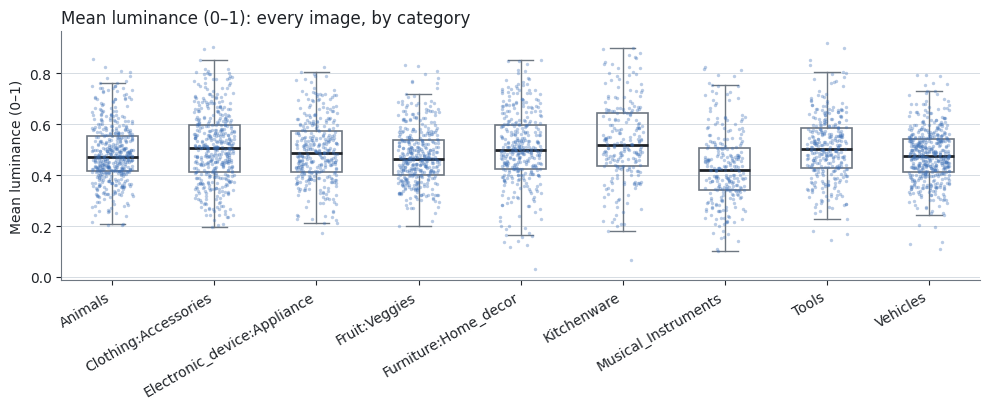

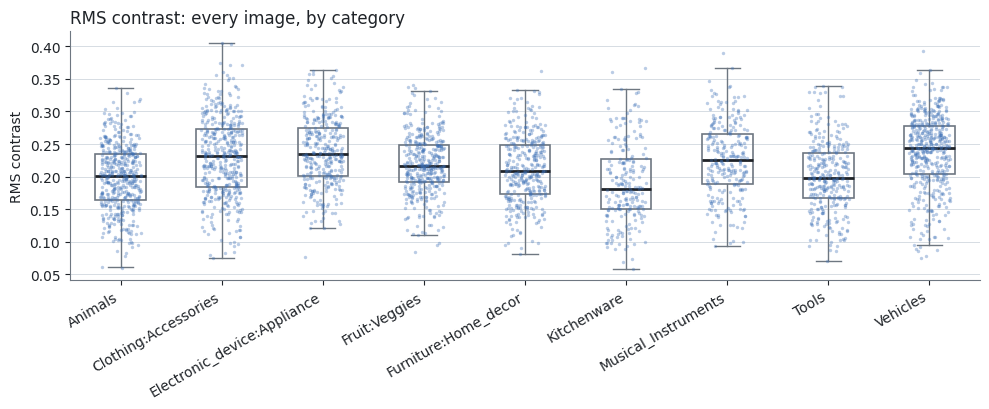

In [10]:
for col, label in MEASURES.items():
    fig, ax = plt.subplots(figsize=(10, 4.2))
    data = [df.loc[df["category"] == c, col] for c in cat_order]
    ax.boxplot(data, widths=0.5, showfliers=False, patch_artist=True,
               boxprops=dict(facecolor="none", edgecolor=MUTED, linewidth=1.2),
               medianprops=dict(color=INK, linewidth=2),
               whiskerprops=dict(color=MUTED), capprops=dict(color=MUTED))
    for i, d in enumerate(data, 1):
        ax.scatter(i + rng.uniform(-0.2, 0.2, len(d)), d, s=6,
                   color=MARK, alpha=0.35, linewidth=0, zorder=3)
    ax.set_xticks(range(1, len(cat_order) + 1))
    ax.set_xticklabels(cat_order, rotation=30, ha="right")
    ax.set_ylabel(label)
    ax.set_title(f"{label}: every image, by category", loc="left", color=INK)
    ax.grid(axis="y", color="#d0d7de", linewidth=0.6)
    ax.set_axisbelow(True)
    plt.tight_layout()
    plt.show()

### Most and least variable subcategories (SD across the 20 images)

In [11]:
for col, label in MEASURES.items():
    s = (df.groupby(["category", "subcategory"])[col].agg(["mean", "std"])
           .rename(columns={"std": "SD"}).sort_values("SD").round(3))
    print(f"\n{label}: subcategory SD ranges from {s['SD'].min():.3f} to {s['SD'].max():.3f}")
    display(pd.concat({"least variable": s.head(5), "most variable": s.tail(5)}))


Mean luminance (0–1): subcategory SD ranges from 0.050 to 0.192


mean     SD
               category             subcategory              
least variable Animals              koala        0.454  0.050
               Vehicles             taxi         0.387  0.052
               Animals              orangutan    0.441  0.058
               Furniture:Home_decor birdhouse    0.466  0.060
               Animals              zebra        0.509  0.064
most variable  Clothing:Accessories tie          0.473  0.174
               Furniture:Home_decor vase         0.591  0.177
               Musical_Instruments  saxophone    0.420  0.182
               Kitchenware          spatula      0.603  0.190
                                    shaker       0.492  0.192


RMS contrast: subcategory SD ranges from 0.026 to 0.086


mean     SD
               category             subcategory              
least variable Furniture:Home_decor doorknocker  0.166  0.026
               Animals              lion         0.178  0.028
               Fruit:Veggies        mango        0.205  0.030
               Vehicles             trolley      0.273  0.030
               Fruit:Veggies        cabbage      0.211  0.030
most variable  Tools                ruler        0.174  0.072
               Kitchenware          corkscrew    0.190  0.074
               Clothing:Accessories t-shirt      0.206  0.075
               Kitchenware          spatula      0.161  0.077
               Clothing:Accessories jacket       0.252  0.086

### Extreme images (|z| > 3 across all images)

In [12]:
for col, label in MEASURES.items():
    z = (df[col] - df[col].mean()) / df[col].std()
    out = df.loc[z.abs() > 3, ["image_id", "category", "subcategory", "filename", col]].copy()
    out["z"] = z[z.abs() > 3]
    print(f"\n{label}: {len(out)} extreme images")
    display(out.round(3).reset_index(drop=True))


Mean luminance (0–1): 10 extreme images


,image_id,category,subcategory,filename,mean_luminance,z
0,img0755,Clothing:Accessories,necklace,necklace_12s.jpg,0.904,3.203
1,img0866,Clothing:Accessories,t-shirt,t-shirt_03s.jpg,0.895,3.131
2,img1764,Furniture:Home_decor,candle,candle_04.JPEG,0.033,-3.545
3,img2078,Kitchenware,goblet,goblet_47.JPEG,0.068,-3.270
4,img2157,Kitchenware,saltshaker,saltshaker_15s.jpg,0.881,3.024
5,img2165,Kitchenware,shaker,shaker_04s.jpg,0.896,3.139
6,img2183,Kitchenware,spatula,spatula_03s.jpg,0.899,3.161
7,img2256,Musical_Instruments,accordion,accordion_24.JPEG,0.103,-3.001
8,img2723,Tools,safety_pin,safety_pin_03s.jpg,0.921,3.333
9,img2734,Tools,safety_pin,safety_pin_12.JPEG,0.899,3.161



RMS contrast: 4 extreme images


,image_id,category,subcategory,filename,rms_contrast,z
0,img0586,Clothing:Accessories,bowtie,bowtie_04.JPEG,0.403,3.295
1,img0664,Clothing:Accessories,jacket,jacket_02s.jpg,0.406,3.344
2,img2337,Musical_Instruments,gong,gong_30.JPEG,0.389,3.056
3,img3094,Vehicles,snowmobile,snowmobile_12_Imagenet.JPEG,0.392,3.106


## Summary (results as of 2026-10-13, 165 subcategories / 3,300 images)

**Yes, the categories differ on both measures. The difference is larger for contrast than for luminance.**

| Measure | ANOVA on subcategory means | Kruskal–Wallis | Mixed model LRT | Controlling for source |
|---|---|---|---|---|
| Mean luminance | F(8,156) = 3.23, p = .002, η² = .14 | H = 25.2, p = .001 | χ²(8) = 25.3, p = .001 | χ²(8) = 25.3, p = .001 |
| RMS contrast | F(8,156) = 8.64, p < .001, η² = .31 | H = 52.3, p < .001 | χ²(8) = 60.5, p < .001 | χ²(8) = 60.6, p < .001 |

- **Luminance:** the effect comes almost entirely from **Musical_Instruments**, which is darker than the other categories (mean 0.43 vs. 0.48–0.53). It differs significantly from Kitchenware, Clothing:Accessories, Tools and Furniture:Home_decor. No other pairs differ.
- **Contrast:** the differences are more widespread (12 of 36 pairs). **Vehicles**, **Electronic_device:Appliance** and **Clothing:Accessories** have higher contrast. **Kitchenware**, **Animals** and **Tools** have lower contrast.
- **Source** (ImageNet vs. THINGS vs. other) does not explain the category differences.
- **Within-category variation is much larger than between-category variation.** Category explains only 3% of the total variation in luminance and 8% in contrast. Most variation lies between images in the same subcategory (77% for luminance, 74% for contrast), and the rest is between subcategories. Some categories are more spread out than others (Levene p < .001): Kitchenware and Musical_Instruments vary most in luminance, and Kitchenware and Clothing:Accessories vary most in contrast. 10 images are extreme in luminance (|z| > 3; very bright white-background objects, or very dark ones such as candle_04 and goblet_47) and 4 in contrast.

**What to do:** if low-level differences matter for your design, you can (a) equate luminance and contrast across images, e.g. with the SHINE toolbox or by matching each image's grayscale mean and SD; (b) swap out the most extreme images or subcategories; or (c) include mean luminance and RMS contrast as covariates in your analysis. Per-image values are saved in `image_luminance_contrast.csv`.